# IN4640 Assignment 1 Transformations and Neighborhood  Filtering

1. Implement the intensity transformation depicted in Fig. 1a on the image shown in Fig. 1b, read as a
grayscale image.

(a) Implement the transformation as a 256-entry lookup table (e.g., using cv.LUT or NumPy indexing),
     and show the original and transformed images side by side.


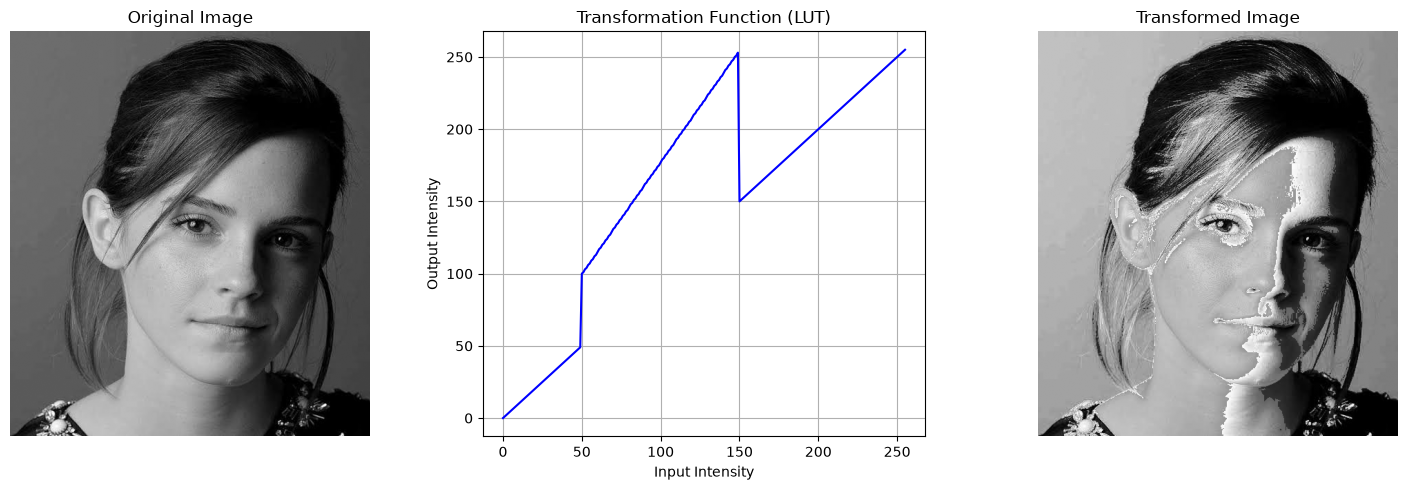

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

img = cv.imread('Images/emma.jpg', cv.IMREAD_GRAYSCALE)


t = np.zeros(256)
t[0:50] = np.arange(0, 50)
t[150:256] = np.arange(150, 256)
t[50:150] = 1.55 * np.arange(50, 150) + 22.5
t = np.clip(t, 0, 255).astype(np.uint8)


img_transformed = cv.LUT(img, t)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].plot(t, color='blue')
axes[1].set_title('Transformation Function (LUT)')
axes[1].set_xlabel('Input Intensity')
axes[1].set_ylabel('Output Intensity')
axes[1].grid(True)

axes[2].imshow(img_transformed, cmap='gray')
axes[2].set_title('Transformed Image')
axes[2].axis('off')

plt.tight_layout()
plt.show()

(b) Explain the visual effect of the transformation. In particular, what happens to pixels with intensities just below and just above 50 and 150?
<br>
<span style="color: blue;"> 
Increases the brightness and contrast of pixels with intensities between 50 and 150.
Pixels below 50 and at or above 150 remain unchanged.
 </span>

## Question 2 – Intensity Transformation for Brain Tissue Enhancement

Apply an intensity transformation similar to Question 1 to accentuate the following tissues in the brain Proton Density (PD) image shown in **Figure 2**:

**(a)** White matter

**(b)** Gray matter

1. Apply a suitable intensity transformation to enhance white matter.
2. Apply a suitable intensity transformation to enhance gray matter.
3. Plot the intensity transformation functions for both cases.
4. Display the resulting enhanced images.
5. State the intensity ranges selected for each tissue and explain how you chose those ranges.



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..246.5].


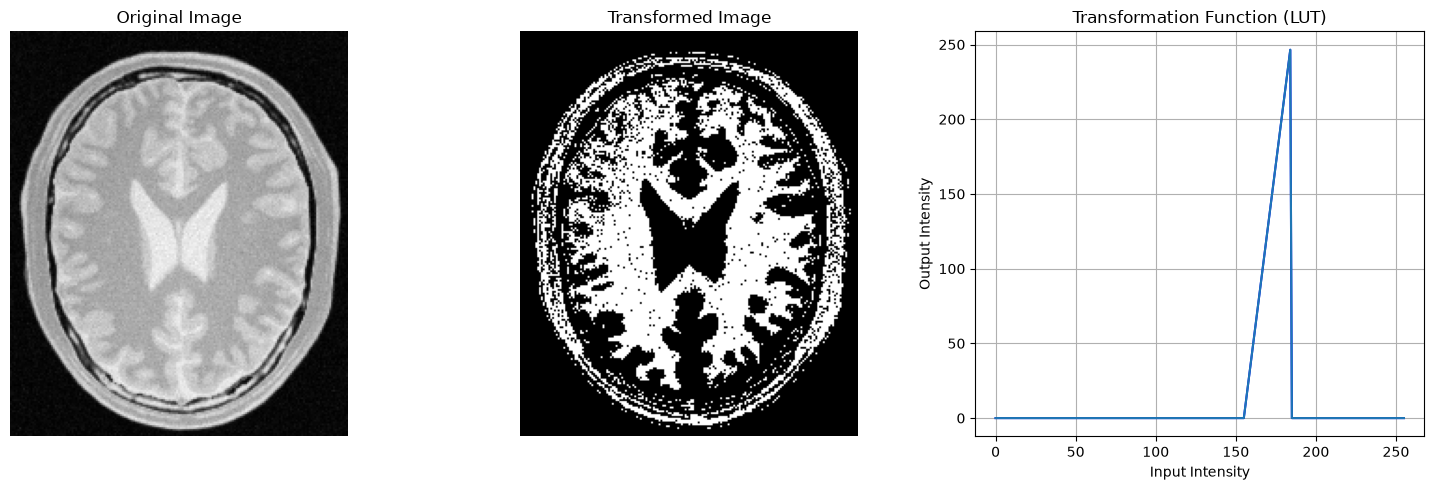

In [6]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

im = cv.imread("Images/brain.png")

t = np.zeros(256)
t[155:185] = 255/30 * np.arange(155, 185) - 255/30*155

g = t[im]

# plot the original image and the transformed image and transformtion function
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(im, cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(g, cmap='gray')
axes[1].set_title('Transformed Image')
axes[1].axis('off')

axes[2].plot(t, color='blue')
axes[2].set_title('Transformation Function (LUT)')
axes[2].set_xlabel('Input Intensity')
axes[2].set_ylabel('Output Intensity')
axes[2].grid(True)

plt.tight_layout()
plt.plot(t)
plt.show()
